# REVELA WLC/OPS Sensitivity — refreshed 2026-10-30

Reproduces baseline scores with the current `wlc-v3` scorer, then tests bounded weight perturbations against the same full Mataasnakahoy cohort. The production scoring formula and saved weights are not changed.

## Scope and safeguards

Inputs are current barangay aggregates collected through read-only database MCP `SELECT`s. No business names, addresses, or business/log IDs are exported. The component and sector aggregates are 16 seconds apart because the MCP does not provide a multi-query snapshot transaction; both query timestamps are preserved in the input. No missing sector labels or Black records are synthesized. This is a relative-priority sensitivity test, not an outcome-accuracy study.

In [1]:
from pathlib import Path
import importlib.util
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

WORKING_DIR = Path.cwd().resolve()
ROOT = next((path for path in (WORKING_DIR, *WORKING_DIR.parents)
             if (path / "revela_backend" / "api" / "analytics" / "scoring.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Could not locate the repository scorer from the notebook working directory.")
BACKEND = ROOT / "revela_backend"
if str(BACKEND) not in sys.path:
    sys.path.insert(0, str(BACKEND))

from api.analytics.dispatch import generate_recommendations
from api.analytics.scoring import MODEL_VERSION, calculate_rankings
from api.analytics.sector_risk import validate_sector_risk_policy
from api.analytics.service import validate_wlc_config

WLC_DIR = ROOT / "analytical performance" / "wlc"
INPUT_PATH = WLC_DIR / "ops_sensitivity_input.csv"
META_PATH = WLC_DIR / "ops_sensitivity_input.meta.json"
CONFIG_PATH = BACKEND / "api" / "analytics" / "wlc_config.json"
print(f"Repository: {ROOT}")
print(f"Current scorer: {MODEL_VERSION}")
print(f"Excel export engine available: {importlib.util.find_spec('openpyxl') is not None}")

Repository: C:\REVELA-prod
Current scorer: wlc-v3
Excel export engine available: True


## Production snapshot

The next code cell loads the fixed barangay-level MCP snapshot and current policy; there is no upload step or hand-edited column mapping.

### Input definitions

- Effective Red/Yellow/Black record counts use distinct geospatial log IDs and the current mapped/reported/inspected-pin predicate.
- Sector input is the categorized active-entity count list; `category: null` remains null so the scorer applies fallback 50.
- Coordinates are means of valid, dispatchable effective Red/Yellow records only; blank pairs stay missing and receive proximity 50 in the scorer.
- Dispatch counts/business identities and inspector availability are aggregate-only operational fields.
- Weights/BPLO come from the checked-in scorer configuration; the editable sector policy comes from the live database row used by the scoring route.

In [2]:
input_df = pd.read_csv(INPUT_PATH, keep_default_na=False)
with META_PATH.open(encoding="utf-8") as metadata_file:
    metadata = json.load(metadata_file)
with CONFIG_PATH.open(encoding="utf-8") as config_file:
    wlc_config = json.load(config_file)
sector_policy = validate_sector_risk_policy(metadata["sector_risk_policy"])
validate_wlc_config(wlc_config)
print("Snapshot rows:", len(input_df))
print("Component snapshot UTC:", metadata["snapshot"]["component_snapshot_utc"])
print("Sector aggregate UTC:", metadata["snapshot"]["sector_aggregate_snapshot_utc"])
print("Policy/model:", MODEL_VERSION, "sector policy", sector_policy["version"])
print("Configured weights (%):", {key: wlc_config[key] for key in ("w1_risk", "w2_sector", "w3_distance")})
print("Baseline snapshot preview:")
display(input_df.head())

Snapshot rows: 16
Component snapshot UTC: 2026-10-30T06:33:07.035Z
Sector aggregate UTC: 2026-10-30T06:33:23.075Z
Policy/model: wlc-v3 sector policy 1
Configured weights (%): {'w1_risk': 68, 'w2_sector': 7, 'w3_distance': 25}
Baseline snapshot preview:


,barangay_id,barangay_name,red_count,yellow_count,black_count,avg_lat,avg_lng,dispatchable_red_count,dispatchable_yellow_count,dispatchable_business_count,sector_category_counts,snapshot_utc,sector_snapshot_utc,active_inspectors,available_inspectors,flagged_count,open_inspection_excluded
0,1,Barangay I,39,0,0,13.954778287179,121.110334151282,39,0,39,"[{""category"":null,""entity_count"":39}]",2026-10-30T06:33:07.035Z,2026-10-30T06:33:23.075Z,2,1,39,False
1,2,Barangay II,46,0,0,13.951055563043,121.116567126087,46,0,46,"[{""category"":null,""entity_count"":46}]",2026-10-30T06:33:07.035Z,2026-10-30T06:33:23.075Z,2,1,46,False
2,3,Barangay II-A,10,0,0,13.958644801250,121.112988442500,8,0,8,"[{""category"":null,""entity_count"":10}]",2026-10-30T06:33:07.035Z,2026-10-30T06:33:23.075Z,2,1,10,True
3,4,Barangay III,22,0,0,13.961249231818,121.108908854545,22,0,22,"[{""category"":null,""entity_count"":22}]",2026-10-30T06:33:07.035Z,2026-10-30T06:33:23.075Z,2,1,22,False
4,5,Barangay IV,8,0,0,13.958609537500,121.117144450000,8,0,8,"[{""category"":null,""entity_count"":8}]",2026-10-30T06:33:07.035Z,2026-10-30T06:33:23.075Z,2,1,8,False


## Snapshot validation

This gate checks full-cohort uniqueness, count consistency, actual missing categories, coordinate-pair coverage, and the fresh snapshot totals before scoring. A failure stops the analysis.

In [3]:
required_columns = {
    "barangay_id", "barangay_name", "red_count", "yellow_count", "black_count",
    "avg_lat", "avg_lng", "dispatchable_red_count", "dispatchable_yellow_count",
    "dispatchable_business_count", "sector_category_counts", "flagged_count",
    "active_inspectors", "available_inspectors",
}
missing_columns = required_columns - set(input_df.columns)
if missing_columns:
    raise ValueError(f"Snapshot is missing required columns: {sorted(missing_columns)}")
if len(input_df) != 16 or input_df["barangay_id"].duplicated().any():
    raise ValueError("Snapshot must contain exactly one row for each of the 16 current barangays.")
for column in ("red_count", "yellow_count", "black_count", "flagged_count",
               "dispatchable_red_count", "dispatchable_yellow_count", "dispatchable_business_count"):
    input_df[column] = pd.to_numeric(input_df[column], errors="raise").astype(int)
if not (input_df["flagged_count"] == input_df[["red_count", "yellow_count", "black_count"]].sum(axis=1)).all():
    raise ValueError("flagged_count does not equal the Red + Yellow + Black record counts.")
if (input_df[["red_count", "yellow_count", "black_count"]] < 0).any().any():
    raise ValueError("Negative flag counts are invalid.")
if input_df[["avg_lat", "avg_lng"]].apply(lambda col: col.eq("")).sum().iloc[0] != input_df[["avg_lat", "avg_lng"]].apply(lambda col: col.eq("")).sum().iloc[1]:
    raise ValueError("Latitude/longitude missingness must occur as a coordinate pair.")
print("Snapshot checks passed: 16 unique barangays; counts reconcile.")
print("Flag totals:", input_df[["red_count", "yellow_count", "black_count"]].sum().to_dict())
print("No-flag barangays:", int((input_df["flagged_count"] == 0).sum()))
print("Missing coordinate pairs:", int(input_df["avg_lat"].eq("").sum()))
print("Snapshot window (seconds):", (pd.Timestamp(metadata["snapshot"]["sector_aggregate_snapshot_utc"]) - pd.Timestamp(metadata["snapshot"]["component_snapshot_utc"])).total_seconds())

Snapshot checks passed: 16 unique barangays; counts reconcile.
Flag totals: {'red_count': 201, 'yellow_count': 21, 'black_count': 0}
No-flag barangays: 5
Missing coordinate pairs: 5
Snapshot window (seconds): 16.04


## Current source-of-truth model

The next cell builds the exact row shape expected by `calculate_rankings()`. No hand-copied scoring formula or sector-score imputation is used. It checks the baseline weights and BPLO against `wlc_config.json`; category-null entity counts remain under the Python `None` key.

In [4]:
config_from_meta = metadata["production_config"]
for key in ("w1_risk", "w2_sector", "w3_distance"):
    if float(config_from_meta["weights_percent"][key]) != float(wlc_config[key]):
        raise ValueError(f"Snapshot {key} does not match the current code configuration.")
for key in ("lat", "lng"):
    config_key = "bplo_lat" if key == "lat" else "bplo_lng"
    if float(config_from_meta["bplo"][key]) != float(wlc_config[config_key]):
        raise ValueError(f"Snapshot BPLO {key} does not match the current code configuration.")

scoring_rows = []
for row in input_df.to_dict(orient="records"):
    category_counts = {}
    category_entries = json.loads(row["sector_category_counts"])
    for entry in category_entries:
        category = entry["category"]
        count = int(entry["entity_count"])
        if count < 0:
            raise ValueError("Sector entity counts cannot be negative.")
        category_counts[category] = category_counts.get(category, 0) + count
    lat = None if row["avg_lat"] == "" else float(row["avg_lat"])
    lng = None if row["avg_lng"] == "" else float(row["avg_lng"])
    scoring_rows.append({
        "barangayID": int(row["barangay_id"]),
        "barangayName": row["barangay_name"],
        "red_count": int(row["red_count"]),
        "yellow_count": int(row["yellow_count"]),
        "black_count": int(row["black_count"]),
        "dispatchable_red_count": int(row["dispatchable_red_count"]),
        "dispatchable_yellow_count": int(row["dispatchable_yellow_count"]),
        "dispatchable_business_count": int(row["dispatchable_business_count"]),
        "avg_lat": lat,
        "avg_lng": lng,
        "sector_category_counts": category_counts,
    })

baseline_weights = {key: float(wlc_config[key]) / 100 for key in ("w1_risk", "w2_sector", "w3_distance")}
sector_null_entities = sum(count for row in scoring_rows for label, count in row["sector_category_counts"].items() if label is None)
sector_known_entities = sum(count for row in scoring_rows for label, count in row["sector_category_counts"].items() if label in sector_policy["categories"])
print("Weights sum:", sum(baseline_weights.values()))
print("Sector entities: known =", sector_known_entities, "; missing-category =", sector_null_entities)
print("Live API score rows are not stored/available through the read-only database connector.")

Weights sum: 1.0
Sector entities: known = 0 ; missing-category = 222
Live API score rows are not stored/available through the read-only database connector.


## Baseline scoring

`calculate_rankings()` computes weighted burden `3×Red + 2×Yellow + 4×Black`, full-cohort maximum normalization, Haversine proximity from BPLO, neutral missing-coordinate/sector fallback, OPS rounding, zero-flag handling, policy bands, and deterministic municipal tie-breaks.

In [5]:
baseline_rankings, baseline_model = calculate_rankings(scoring_rows, wlc_config, sector_policy)
baseline = pd.DataFrame(baseline_rankings).sort_values("rank").reset_index(drop=True)
baseline["priority_band"] = baseline["risk_level"]
baseline["barangay_id"] = baseline["barangayID"]
baseline["barangay_name"] = baseline["barangayName"]
Q_MAX = int(baseline_model["reference_max_burden"])
print("Model:", baseline_model["version"], "Q_max:", Q_MAX)
print("Priority thresholds:", baseline_model["priority_thresholds"])
print("Sector fallback score / affected barangays:", baseline_model["sector_fallback_score"], "/", baseline_model["sector_fallback_count"])
show_columns = ["rank", "barangay_id", "barangay_name", "red_count", "yellow_count", "black_count",
                "weighted_burden", "risk_score", "sector_score", "distance_km", "proximity_score", "ops_score", "priority_band"]
display(baseline[show_columns])

Model: wlc-v3 Q_max: 138
Priority thresholds: {'High': 60, 'Medium': 30}
Sector fallback score / affected barangays: 50 / 16


,rank,barangay_id,barangay_name,red_count,yellow_count,black_count,weighted_burden,risk_score,sector_score,distance_km,proximity_score,ops_score,priority_band
0,1,2,Barangay II,46,0,0,138,100.0,50.0,1.063,94.7,95.2,High
1,2,1,Barangay I,39,0,0,117,84.8,50.0,0.774,96.1,85.2,High
2,3,7,Barangay Bubuyan,12,21,0,78,56.5,50.0,2.250,88.7,64.1,High
3,4,4,Barangay III,22,0,0,66,47.8,50.0,0.615,96.9,60.2,High
4,5,16,Barangay Upa,18,0,0,54,39.1,50.0,0.745,96.3,54.2,Medium
5,6,9,Barangay Loob,17,0,0,51,37.0,50.0,1.990,90.1,51.2,Medium
6,7,8,Barangay Calingatan,14,0,0,42,30.4,50.0,0.664,96.7,48.3,Medium
7,8,15,Barangay Santol,13,0,0,39,28.3,50.0,1.630,91.8,45.7,Medium
8,9,3,Barangay II-A,10,0,0,30,21.7,50.0,0.259,98.7,42.9,Medium
9,10,5,Barangay IV,8,0,0,24,17.4,50.0,0.345,98.3,39.9,Medium


### Baseline interpretation

The displayed ranks and component values come directly from the current scorer. Inspect the 16-row baseline and check that all five no-flag barangays remain score 0 despite the neutral sector/proximity components.

## Baseline parity gate

A separate formula check reconstructs OPS from the scorer's rounded components and configured weights, then checks the exact rank tie-break. A fresh second scorer call at the baseline is also compared row-by-row. This verifies notebook/current-checkout parity; it is **not** an independent live API deployment comparison.

In [6]:
weight_keys = ("w1_risk", "w2_sector", "w3_distance")
formula_scores = []
for row in baseline_rankings:
    if row["flagged_count"] == 0:
        formula_scores.append(0.0)
    else:
        formula_scores.append(round(
            baseline_weights["w1_risk"] * row["risk_score"]
            + baseline_weights["w2_sector"] * row["sector_score"]
            + baseline_weights["w3_distance"] * row["proximity_score"], 1))
formula_diff = np.abs(np.asarray(formula_scores) - baseline["ops_score"].to_numpy(dtype=float))
second_baseline, _ = calculate_rankings(scoring_rows, wlc_config, sector_policy)
second_by_id = {row["barangayID"]: row for row in second_baseline}
repeat_diff = np.array([abs(row["ops_score"] - second_by_id[row["barangayID"]]["ops_score"]) for row in baseline_rankings])
repeat_rank_match = all(row["rank"] == second_by_id[row["barangayID"]]["rank"] for row in baseline_rankings)
PARITY_MAX_ABS_DIFF = float(max(formula_diff.max(initial=0.0), repeat_diff.max(initial=0.0)))
PARITY_PASSED = PARITY_MAX_ABS_DIFF <= 0.1 and repeat_rank_match
parity_table = baseline[["barangayID", "barangayName", "ops_score", "rank"]].copy()
parity_table["formula_ops"] = formula_scores
parity_table["abs_ops_difference"] = formula_diff
parity_table["repeat_score_difference"] = repeat_diff
print("Maximum baseline OPS difference:", PARITY_MAX_ABS_DIFF)
print("Repeated scorer ranks match:", repeat_rank_match)
print("Parity passed:", PARITY_PASSED)
display(parity_table)
if not PARITY_PASSED:
    raise ValueError("Baseline parity failed; do not interpret sensitivity scenarios.")

Maximum baseline OPS difference: 0.0
Repeated scorer ranks match: True
Parity passed: True


,barangayID,barangayName,ops_score,rank,formula_ops,abs_ops_difference,repeat_score_difference
0,2,Barangay II,95.2,1,95.2,0.0,0.0
1,1,Barangay I,85.2,2,85.2,0.0,0.0
2,7,Barangay Bubuyan,64.1,3,64.1,0.0,0.0
3,4,Barangay III,60.2,4,60.2,0.0,0.0
4,16,Barangay Upa,54.2,5,54.2,0.0,0.0
5,9,Barangay Loob,51.2,6,51.2,0.0,0.0
6,8,Barangay Calingatan,48.3,7,48.3,0.0,0.0
7,15,Barangay Santol,45.7,8,45.7,0.0,0.0
8,3,Barangay II-A,42.9,9,42.9,0.0,0.0
9,5,Barangay IV,39.9,10,39.9,0.0,0.0


## Bounded weight scenarios

No documented AHP interval or operational weight range was found. The exploratory local stress test varies each criterion by no more than ±10 percentage points from the interview-derived 68/7/25 baseline, in 5-point increments, while requiring all three weights to remain 0–100 and sum to 100. This is intentionally local, not a proposal to change policy.

In [8]:
if not PARITY_PASSED:
    raise ValueError("Sensitivity is blocked because baseline parity failed.")
base_percent = {"risk": int(wlc_config["w1_risk"]), "sector": int(wlc_config["w2_sector"]), "proximity": int(wlc_config["w3_distance"])}
scenario_specs = [{"scenario_id": "baseline", "is_baseline": True, **{f"w_{key}": value for key, value in base_percent.items()}}]
for delta_risk in (-10, -5, 0, 5, 10):
    for delta_sector in (-10, -5, 0, 5, 10):
        delta_proximity = -delta_risk - delta_sector
        if delta_proximity not in (-10, -5, 0, 5, 10):
            continue
        values = {"risk": base_percent["risk"] + delta_risk,
                  "sector": base_percent["sector"] + delta_sector,
                  "proximity": base_percent["proximity"] + delta_proximity}
        if min(values.values()) < 0 or max(values.values()) > 100 or sum(values.values()) != 100:
            continue
        if values == base_percent:
            continue
        scenario_specs.append({"scenario_id": f"r{values['risk']:02d}_s{values['sector']:02d}_p{values['proximity']:02d}",
                               "is_baseline": False, **{f"w_{key}": value for key, value in values.items()}})
if len(scenario_specs) != 16:
    raise AssertionError(f"Expected 16 total local scenarios including baseline, got {len(scenario_specs)}")
print("Scenario count including baseline:", len(scenario_specs))
display(pd.DataFrame(scenario_specs))

Scenario count including baseline: 16


,scenario_id,is_baseline,w_risk,w_sector,w_proximity
0,baseline,True,68,7,25
1,r58_s07_p35,False,58,7,35
2,r58_s12_p30,False,58,12,30
3,r58_s17_p25,False,58,17,25
4,r63_s02_p35,False,63,2,35
5,r63_s07_p30,False,63,7,30
6,r63_s12_p25,False,63,12,25
7,r63_s17_p20,False,63,17,20
8,r68_s02_p30,False,68,2,30
9,r68_s12_p20,False,68,12,20


## Re-score and dispatch

Every scenario is evaluated by calling the same production `calculate_rankings()` function with only the three weights changed. The same full-cohort burden denominator, source inputs, sector policy, and tie-break remain fixed. Current dispatch recommendations are generated by the production dispatch helper using the aggregate snapshot of available inspectors.

In [9]:
if not PARITY_PASSED:
    raise ValueError("Sensitivity is blocked because baseline parity failed.")
scenario_rankings = {}
scenario_models = {}
for spec in scenario_specs:
    scenario_config = dict(wlc_config)
    scenario_config.update({"w1_risk": spec["w_risk"], "w2_sector": spec["w_sector"], "w3_distance": spec["w_proximity"]})
    ranked, model = calculate_rankings(scoring_rows, scenario_config, sector_policy)
    scenario_rankings[spec["scenario_id"]] = pd.DataFrame(ranked).sort_values("rank").reset_index(drop=True)
    scenario_models[spec["scenario_id"]] = model
baseline_scenario = scenario_rankings["baseline"]
if not np.array_equal(baseline_scenario["ops_score"].to_numpy(), baseline["ops_score"].to_numpy()):
    raise AssertionError("Sensitivity baseline scores differ from the current scorer.")
if not np.array_equal(baseline_scenario["rank"].to_numpy(), baseline["rank"].to_numpy()):
    raise AssertionError("Sensitivity baseline ranks differ from the current scorer.")
print("Scored scenarios:", len(scenario_rankings))
print("Baseline score and rank parity: exact")

Scored scenarios: 16
Baseline score and rank parity: exact


## Rank stability and priority bands

The next results compare each perturbation with baseline top priorities, full ranking correlation/rank movement, and the scorer's High/Medium/Low bands at 60/30. The current band labels are policy thresholds, not violation probabilities.

In [10]:
baseline_by_name = baseline.set_index("barangayName")
baseline_order = baseline["barangayName"].tolist()
baseline_top_sets = {k: set(baseline.head(k)["barangayName"]) for k in (1, 3, 5)}
scenario_summary_rows = []
scenario_rank_rows = []
dispatch_rows = []
available_inspectors = int(input_df["available_inspectors"].iloc[0])
active_inspectors = int(input_df["active_inspectors"].iloc[0])
for spec in scenario_specs:
    sid = spec["scenario_id"]
    frame = scenario_rankings[sid]
    current = frame.set_index("barangayName")
    rank_changes = (current.loc[baseline_order, "rank"].to_numpy(dtype=int)
                    - baseline_by_name.loc[baseline_order, "rank"].to_numpy(dtype=int))
    band_agreement = current.loc[baseline_order, "risk_level"].to_numpy() == baseline_by_name.loc[baseline_order, "risk_level"].to_numpy()
    row = {**spec,
           "spearman_rank_correlation": float(pd.Series(current.loc[baseline_order, "rank"].to_numpy()).corr(pd.Series(baseline_by_name.loc[baseline_order, "rank"].to_numpy()), method="spearman")),
           "mean_abs_rank_change": float(np.abs(rank_changes).mean()),
           "max_abs_rank_change": int(np.abs(rank_changes).max()),
           "top1_overlap": len(set(frame.head(1)["barangayName"]) & baseline_top_sets[1]),
           "top3_overlap": len(set(frame.head(3)["barangayName"]) & baseline_top_sets[3]),
           "top5_overlap": len(set(frame.head(5)["barangayName"]) & baseline_top_sets[5]),
           "band_agreement_count": int(band_agreement.sum()),
           "band_agreement_pct": float(band_agreement.mean() * 100),
           "band_changes": int((~band_agreement).sum())}
    scenario_summary_rows.append(row)
    for record in frame.to_dict(orient="records"):
        scenario_rank_rows.append({"scenario_id": sid, "barangay_id": record["barangayID"],
                                   "barangay_name": record["barangayName"], "rank": record["rank"],
                                   "ops_score": record["ops_score"], "priority_band": record["risk_level"],
                                   "priority_label": record["priority_label"]})
    recommendations = generate_recommendations(frame.to_dict(orient="records"), available_inspectors, scenario_models[sid]["weights"])
    dispatch_rows.extend({"scenario_id": sid, **item} for item in recommendations)
scenario_summary = pd.DataFrame(scenario_summary_rows)
scenario_rankings_long = pd.DataFrame(scenario_rank_rows)
dispatch_comparison = pd.DataFrame(dispatch_rows)
print("Summary across all scenarios:")
display(scenario_summary[["scenario_id", "w_risk", "w_sector", "w_proximity", "spearman_rank_correlation", "mean_abs_rank_change", "max_abs_rank_change", "top3_overlap", "band_agreement_pct", "band_changes"]])
print("Active / available inspectors:", active_inspectors, "/", available_inspectors)
print("Dispatchable barangays / identities:", int((input_df["dispatchable_business_count"] > 0).sum()), "/", int(input_df["dispatchable_business_count"].sum()))
print("Baseline dispatch recommendations:")
display(dispatch_comparison.loc[dispatch_comparison["scenario_id"] == "baseline", ["barangayName", "rank", "inspectors", "allocation_status", "dispatchable_business_count"]])

Summary across all scenarios:


,scenario_id,w_risk,w_sector,w_proximity,spearman_rank_correlation,mean_abs_rank_change,max_abs_rank_change,top3_overlap,band_agreement_pct,band_changes
0,baseline,68,7,25,1.0,0.0,0,3,100.00,0
1,r58_s07_p35,58,7,35,1.0,0.0,0,3,93.75,1
2,r58_s12_p30,58,12,30,1.0,0.0,0,3,93.75,1
3,r58_s17_p25,58,17,25,1.0,0.0,0,3,93.75,1
4,r63_s02_p35,63,2,35,1.0,0.0,0,3,93.75,1
5,r63_s07_p30,63,7,30,1.0,0.0,0,3,93.75,1
6,r63_s12_p25,63,12,25,1.0,0.0,0,3,93.75,1
7,r63_s17_p20,63,17,20,1.0,0.0,0,3,93.75,1
8,r68_s02_p30,68,2,30,1.0,0.0,0,3,93.75,1
9,r68_s12_p20,68,12,20,1.0,0.0,0,3,93.75,1


Active / available inspectors: 2 / 1
Dispatchable barangays / identities: 11 / 220
Baseline dispatch recommendations:


,barangayName,rank,inspectors,allocation_status,dispatchable_business_count
0,Barangay II,1,1,ready,46
1,Barangay I,2,0,deferred,39
2,Barangay Bubuyan,3,0,deferred,33


### What the comparisons mean

- Rank correlations and rank shifts describe ordering stability, not prediction quality.
- Band agreement uses the scorer's `risk_level` field so unflagged barangays still remain in the cohort; their OPS is forced to 0 by the model.
- Dispatch recommendations are the exact top-three eligible destinations after current-score ordering; only the one available inspector can be allocated.

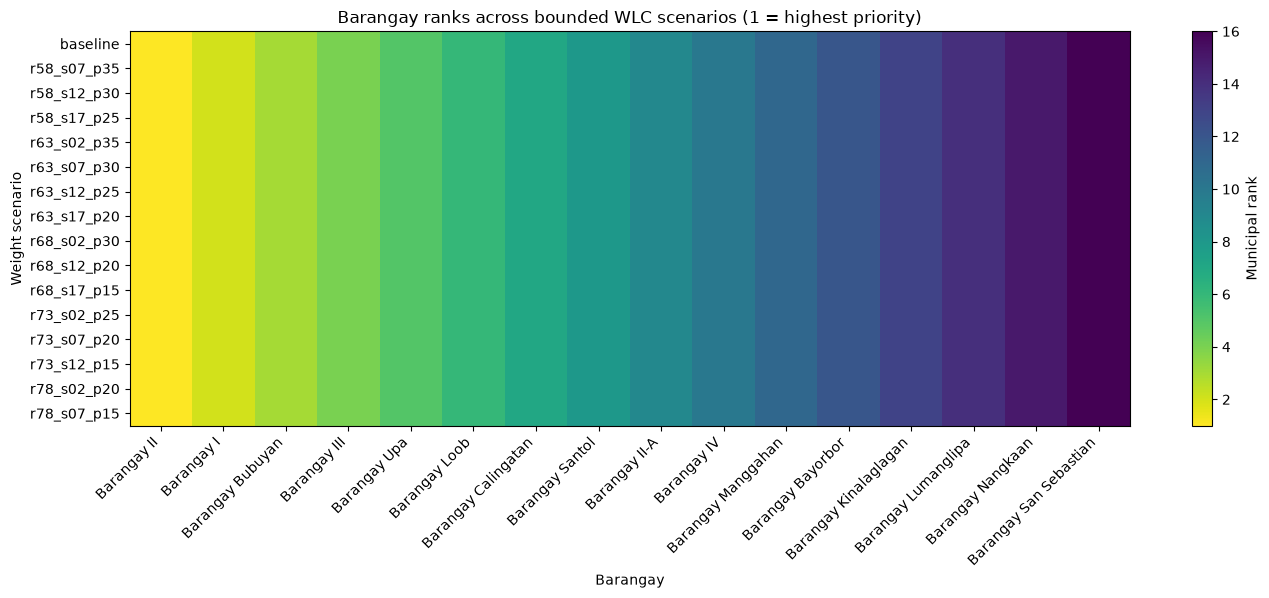

Top-priority frequency across scenarios:


,top_three_scenario_count
barangay_name,
Barangay Bubuyan,16
Barangay I,16
Barangay II,16


In [11]:
rank_matrix = scenario_rankings_long.pivot(index="scenario_id", columns="barangay_name", values="rank")
rank_matrix = rank_matrix.loc[[spec["scenario_id"] for spec in scenario_specs], baseline_order]
fig, ax = plt.subplots(figsize=(14, max(5, 0.38 * len(rank_matrix))))
image = ax.imshow(rank_matrix.to_numpy(), aspect="auto", cmap="viridis_r", vmin=1, vmax=len(baseline_order))
ax.set_xticks(np.arange(len(baseline_order)))
ax.set_xticklabels(baseline_order, rotation=45, ha="right")
ax.set_yticks(np.arange(len(rank_matrix)))
ax.set_yticklabels(rank_matrix.index)
ax.set_title("Barangay ranks across bounded WLC scenarios (1 = highest priority)")
ax.set_xlabel("Barangay")
ax.set_ylabel("Weight scenario")
fig.colorbar(image, ax=ax, label="Municipal rank")
fig.tight_layout()
plt.show()
print("Top-priority frequency across scenarios:")
top_frequency = scenario_rankings_long.loc[scenario_rankings_long["rank"] <= 3].groupby("barangay_name").size().sort_values(ascending=False)
display(top_frequency.rename("top_three_scenario_count").to_frame())

## Visual interpretation

The heatmap shows rank movement by scenario; the accompanying table counts how often a barangay appears in the top three. Read alongside the baseline score/band and dispatch table, because a small rank shift can matter when a barangay crosses a dispatch or 30/60 band boundary.

In [12]:
RESULT_DIR = WLC_DIR / "result"
RESULT_DIR.mkdir(exist_ok=True)
baseline_export = baseline[["rank", "barangayID", "barangayName", "red_count", "yellow_count", "black_count",
                            "weighted_burden", "risk_score", "sector_score", "distance_km", "proximity_score",
                            "ops_score", "risk_level", "priority_label", "dispatchable_count",
                            "dispatchable_business_count", "location_missing"]].copy()
scenario_summary.to_csv(RESULT_DIR / "ops_sensitivity_scenario_summary.csv", index=False)
baseline_export.to_csv(RESULT_DIR / "ops_sensitivity_baseline.csv", index=False)
scenario_rankings_long.to_csv(RESULT_DIR / "ops_sensitivity_scenario_rankings.csv", index=False)
dispatch_comparison.to_csv(RESULT_DIR / "ops_sensitivity_dispatch.csv", index=False)
scenario_summary.to_csv(WLC_DIR / "ops_sensitivity_scenario_summary.csv", index=False)
with pd.ExcelWriter(RESULT_DIR / "ops_sensitivity_results.xlsx", engine="openpyxl") as writer:
    baseline_export.to_excel(writer, sheet_name="baseline", index=False)
    scenario_summary.to_excel(writer, sheet_name="scenario_summary", index=False)
    scenario_rankings_long.to_excel(writer, sheet_name="scenario_rankings", index=False)
    dispatch_comparison.to_excel(writer, sheet_name="dispatch", index=False)
print("Refreshed exports in:", RESULT_DIR)
print("CSV and Excel sheets written for baseline, scenarios, rankings, and dispatch.")

Refreshed exports in: C:\REVELA-prod\analytical performance\wlc\result
CSV and Excel sheets written for baseline, scenarios, rankings, and dispatch.


## Exports

The next cell writes fresh baseline, scenario, rank, and dispatch CSVs plus a four-sheet Excel workbook. These outputs are derived only from the fixed snapshot and the current scorer.

## Limitations

The scoring component/sector queries ran 16 seconds apart rather than inside one cross-query transaction. The connected read-only MCP does not expose a live API score response, so parity is against the current checkout's scorer, not independently against the running deployment. There is no documented AHP/operational range; perturbations are exploratory. Five barangays have no dispatchable coordinates, and current active-flag sector categories are all missing.

In [14]:
expected_rows = len(input_df)
if expected_rows != 16 or len(baseline) != expected_rows:
    raise AssertionError("The refreshed analysis does not contain the full barangay cohort.")
if len(scenario_specs) != 16 or len(scenario_summary) != 16:
    raise AssertionError("The refreshed scenario set is incomplete.")
if not PARITY_PASSED:
    raise AssertionError("Current-scorer parity did not pass.")
if int(input_df["black_count"].sum()) != 0:
    raise AssertionError("Unexpected Black records in snapshot; inspect source data instead of assuming them.")
if sector_known_entities != 0 or sector_null_entities != int(input_df["flagged_count"].sum()):
    raise AssertionError("Missing sector categories were altered or known-sector coverage changed.")
if (input_df["dispatchable_business_count"] > input_df["flagged_count"]).any():
    raise AssertionError("Dispatchable business identities exceed the flagged-record count.")
print("Final checks passed: current scorer parity, full cohort, valid scenarios, actual Black=0, null sectors preserved.")

Final checks passed: current scorer parity, full cohort, valid scenarios, actual Black=0, null sectors preserved.


## Refreshed analysis summary

Run results are presented in the preceding tables and outputs. The baseline uses the current `wlc-v3` implementation and 68/7/25 weights. Results describe sensitivity within the stated local perturbation range only; they do not recalibrate weights or change live policy. Deployment parity remains unverified because no live API score response was available.